# DATA (load, select)

Paste MAPILLARY_TOKEN: ··········
{
  "id": "842149990032290",
  "sequence": "kdco8jujomymv4vcbnkxik",
  "captured_at": 1440247237865,
  "compass_angle": 84.749017202418,
  "geometry": {
    "type": "Point",
    "coordinates": [
      -89.214663333333,
      42.28008
    ]
  },
  "height": 1920,
  "width": 2560,
  "thumb_1024_url": "https://scontent-ord5-1.xx.fbcdn.net/m1/v/t6/An8akNT_-q7w0WCUDZgUVwhueZ0UkCIZ65qlosYJBt0pIfjyNZf46W0PvzCSX5x1GowfFJLHyTGHQaQQVrDtHyycwW4DtDQcncYB-pe2LZlz4k77FnwzvymKv8em0yX8lbxtAmT2yjDoyF6Ic9CzCA?stp=s1024x768&edm=ALXxkZ8EAAAA&_nc_gid=_Gmqjzsuxnth95KcY-4WOQ&_nc_oc=Adr-WD-wVnk140TVutr5OVBe8eb3C14kvq2keOSJYTEqhZFwXLjIp_F8rYXdiCuH51I&ccb=10-5&oh=00_Af6gftcp1QrCfs0QgkmUABM8NT-7nJQtxFsLuQLHUMczPQ&oe=6A3542BC&_nc_sid=201bca",
  "thumb_2048_url": "https://scontent-ord5-1.xx.fbcdn.net/m1/v/t6/An8akNT_-q7w0WCUDZgUVwhueZ0UkCIZ65qlosYJBt0pIfjyNZf46W0PvzCSX5x1GowfFJLHyTGHQaQQVrDtHyycwW4DtDQcncYB-pe2LZlz4k77FnwzvymKv8em0yX8lbxtAmT2yjDoyF6Ic9CzCA?stp=s2048x1536&edm=ALXxk

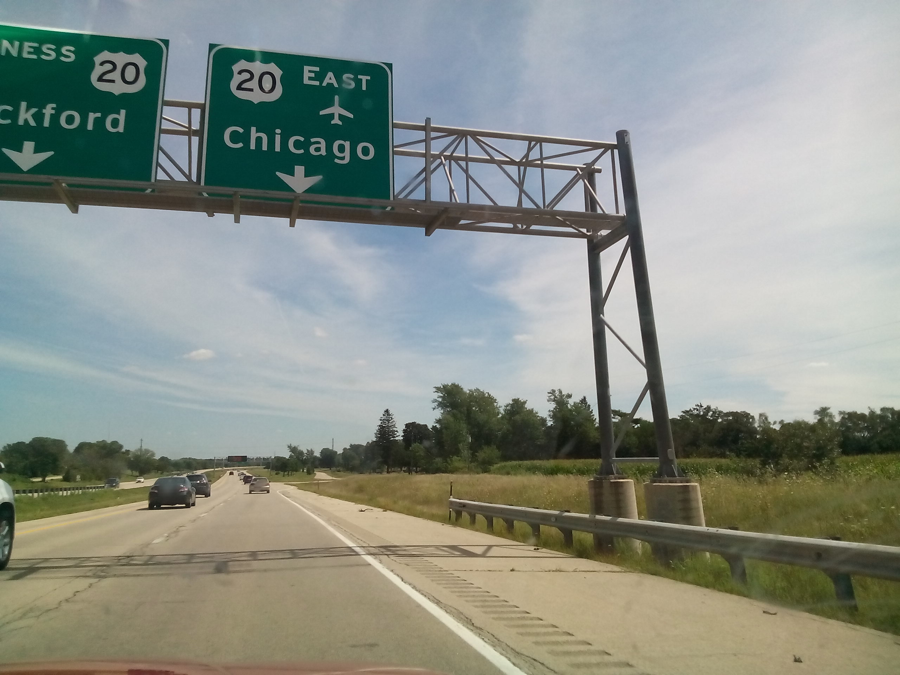

sequence_id: kdco8jujomymv4vcbnkxik


In [2]:
# =========================
# 1. Mapillary: download target image and its sequence
# =========================

import os
import math
import json
import requests
import pandas as pd
from pathlib import Path
from getpass import getpass
from PIL import Image
from io import BytesIO
from IPython.display import display

IMAGE_ID = "842149990032290"

SAVE_ROOT = Path("/content/mapillary_idot_pilot")
IMAGE_DIR = SAVE_ROOT / "single_image"
SEQ_DIR = SAVE_ROOT / "sequence_images"
SAVE_ROOT.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)
SEQ_DIR.mkdir(exist_ok=True)

MAPILLARY_TOKEN = os.getenv("MAPILLARY_TOKEN", "").strip()
if not MAPILLARY_TOKEN:
    MAPILLARY_TOKEN = getpass("Paste MAPILLARY_TOKEN: ").strip()
    os.environ["MAPILLARY_TOKEN"] = MAPILLARY_TOKEN

def mapillary_get(url, params=None):
    params = params or {}
    params["access_token"] = MAPILLARY_TOKEN
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    return r.json()

def download_img(url, out_path):
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    img = Image.open(BytesIO(r.content)).convert("RGB")
    img.save(out_path, quality=95)
    return img

fields = ",".join([
    "id",
    "sequence",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url",
])

meta = mapillary_get(
    f"https://graph.mapillary.com/{IMAGE_ID}",
    params={"fields": fields},
)

print(json.dumps(meta, indent=2)[:2000])

img_url = meta.get("thumb_original_url") or meta.get("thumb_2048_url") or meta.get("thumb_1024_url")
target_path = IMAGE_DIR / f"mapillary_{IMAGE_ID}.jpg"
target_img = download_img(img_url, target_path)

print("Target image saved:", target_path)
print("Target image size:", target_img.size)
display(target_img.resize((900, int(900 * target_img.height / target_img.width))))

sequence_id = meta.get("sequence")
print("sequence_id:", sequence_id)

In [3]:
# =========================
# Download images from the same Mapillary sequence
# Correct API: /image_ids?sequence_id=...
# =========================

import time
import pandas as pd
from tqdm.auto import tqdm

if not sequence_id:
    raise RuntimeError("This image does not expose a sequence id. Try another IMAGE_ID.")

seq_id_url = "https://graph.mapillary.com/image_ids"
seq_id_rows = []
next_url = seq_id_url
next_params = {
    "sequence_id": sequence_id,
    "limit": 1000,
}

while next_url:
    data = mapillary_get(next_url, next_params)
    seq_id_rows.extend(data.get("data", []))

    paging = data.get("paging", {})
    next_url = paging.get("next")
    next_params = {} if next_url else None

if len(seq_id_rows) == 0:
    raise RuntimeError(
        f"No image ids returned for sequence_id={sequence_id}. "
        "This may mean the token cannot access this sequence, or the image has stale sequence metadata."
    )

seq_image_ids = [str(x["id"]) for x in seq_id_rows if "id" in x]
print("Sequence image id count:", len(seq_image_ids))
print(seq_image_ids[:10])

Sequence image id count: 3
['3834223203361021', '841075526761082', '842149990032290']


In [4]:
# =========================
# Fetch metadata for each image id, then download sequence images
# =========================

seq_fields = ",".join([
    "id",
    "sequence",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url",
])

seq_meta_rows = []

for image_id in tqdm(seq_image_ids, desc="Fetching image metadata"):
    try:
        row = mapillary_get(
            f"https://graph.mapillary.com/{image_id}",
            params={"fields": seq_fields},
        )
        seq_meta_rows.append(row)
        time.sleep(0.05)  # avoid rate-limit
    except Exception as e:
        print("metadata failed:", image_id, e)

seq_df = pd.DataFrame(seq_meta_rows)

if seq_df.empty:
    raise RuntimeError("Sequence ids were returned, but metadata fetch failed for all images.")

seq_df["captured_at"] = pd.to_datetime(seq_df["captured_at"], unit="ms", errors="coerce")
seq_df = seq_df.sort_values("captured_at").reset_index(drop=True)

display(seq_df[["id", "captured_at", "compass_angle", "height", "width"]].head())
print("Sequence metadata count:", len(seq_df))

MAX_SEQ_DOWNLOAD = min(40, len(seq_df))

downloaded = []

for i, row in tqdm(seq_df.head(MAX_SEQ_DOWNLOAD).iterrows(), total=MAX_SEQ_DOWNLOAD, desc="Downloading images"):
    url = row.get("thumb_original_url") or row.get("thumb_2048_url") or row.get("thumb_1024_url")
    if not isinstance(url, str) or not url:
        print("No image URL:", row["id"])
        continue

    out = SEQ_DIR / f"{i:04d}_mapillary_{row['id']}.jpg"
    if not out.exists():
        try:
            download_img(url, out)
        except Exception as e:
            print("download failed:", row["id"], e)
            continue

    downloaded.append({
        "local_path": str(out),
        "image_id": row["id"],
        "captured_at": row["captured_at"],
        "compass_angle": row.get("compass_angle"),
        "geometry": row.get("geometry"),
    })

download_df = pd.DataFrame(downloaded)
download_df.to_csv(SAVE_ROOT / "sequence_download_manifest.csv", index=False)

print("Downloaded:", len(download_df))
print("Manifest:", SAVE_ROOT / "sequence_download_manifest.csv")
display(download_df.head())

Fetching image metadata:   0%|          | 0/3 [00:00<?, ?it/s]

,id,captured_at,compass_angle,height,width
0,3834223203361021,2015-08-22 12:40:31.363,88.450325,1920,2560
1,841075526761082,2015-08-22 12:40:35.640,86.560327,1920,2560
2,842149990032290,2015-08-22 12:40:37.865,84.749017,1920,2560


Sequence metadata count: 3


Downloaded: 3
Manifest: /content/mapillary_idot_pilot/sequence_download_manifest.csv


,local_path,image_id,captured_at,compass_angle,geometry
0,/content/mapillary_idot_pilot/sequence_images/...,3834223203361021,2015-08-22 12:40:31.363,88.450325,"{'type': 'Point', 'coordinates': [-89.217095, ..."
1,/content/mapillary_idot_pilot/sequence_images/...,841075526761082,2015-08-22 12:40:35.640,86.560327,"{'type': 'Point', 'coordinates': [-89.21572166..."
2,/content/mapillary_idot_pilot/sequence_images/...,842149990032290,2015-08-22 12:40:37.865,84.749017,"{'type': 'Point', 'coordinates': [-89.21466333..."


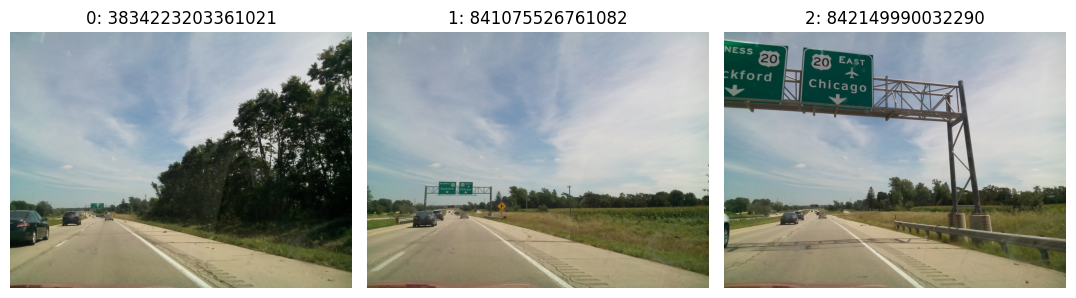

In [5]:
# =========================
# Quick preview grid for downloaded sequence
# =========================

import math
import matplotlib.pyplot as plt
from PIL import Image

preview_paths = download_df["local_path"].tolist()

n = min(20, len(preview_paths))
cols = 5
rows = math.ceil(n / cols)

plt.figure(figsize=(18, 4 * rows))

for k, path in enumerate(preview_paths[:n]):
    img = Image.open(path).convert("RGB")
    plt.subplot(rows, cols, k + 1)
    plt.imshow(img)
    plt.title(f"{k}: {Path(path).name.split('_')[-1].replace('.jpg', '')}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# =========================
# 1. Search nearby Mapillary images around current IMAGE_ID
# =========================

import os
import math
import time
import json
import requests
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

SEARCH_ROOT = SAVE_ROOT / "nearby_sequence_search"
SEARCH_ROOT.mkdir(parents=True, exist_ok=True)

def lonlat_from_geometry(g):
    # Mapillary geometry usually: {"type": "Point", "coordinates": [lon, lat]}
    if isinstance(g, dict) and "coordinates" in g:
        lon, lat = g["coordinates"][:2]
        return float(lon), float(lat)
    return None, None

target_lon, target_lat = lonlat_from_geometry(meta.get("geometry"))
print("target_lon, target_lat:", target_lon, target_lat)

if target_lon is None:
    raise RuntimeError("No geometry found for current IMAGE_ID.")

def bbox_around_lonlat(lon, lat, radius_m=800):
    # approximate conversion
    dlat = radius_m / 111_320
    dlon = radius_m / (111_320 * math.cos(math.radians(lat)))
    return [lon - dlon, lat - dlat, lon + dlon, lat + dlat]

bbox = bbox_around_lonlat(target_lon, target_lat, radius_m=1200)
bbox_str = ",".join(map(str, bbox))
print("bbox:", bbox_str)

nearby_fields = ",".join([
    "id",
    "sequence",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url",
])

nearby_rows = []
next_url = "https://graph.mapillary.com/images"
next_params = {
    "bbox": bbox_str,
    "fields": nearby_fields,
    "limit": 2000,
}

while next_url:
    data = mapillary_get(next_url, next_params)
    nearby_rows.extend(data.get("data", []))

    paging = data.get("paging", {})
    next_url = paging.get("next")
    next_params = {} if next_url else None

    # 避免一次拉太多；先够用即可
    if len(nearby_rows) >= 5000:
        break

nearby_df = pd.DataFrame(nearby_rows)
print("nearby image count:", len(nearby_df))

if nearby_df.empty:
    raise RuntimeError("No nearby Mapillary images found. Try increasing radius_m.")

nearby_df["captured_at"] = pd.to_datetime(nearby_df["captured_at"], unit="ms", errors="coerce")
nearby_df["lon"] = nearby_df["geometry"].apply(lambda g: lonlat_from_geometry(g)[0])
nearby_df["lat"] = nearby_df["geometry"].apply(lambda g: lonlat_from_geometry(g)[1])

display(nearby_df[["id", "sequence", "captured_at", "compass_angle", "lon", "lat"]].head())

target_lon, target_lat: -89.214663333333 42.28008
bbox: -89.22923319887828,42.26930026590011,-89.20009346778771,42.29085973409989
nearby image count: 33


,id,sequence,captured_at,compass_angle,lon,lat
0,1005191023350589,7o4pqpks6j8vnnlj7c6f3e,2015-08-22 12:40:33.415,88.060956,-89.216413,42.280062
1,159208579450492,jqupfbxwn5pkb3slqz07ig,2015-08-22 12:40:03.262,88.910084,-89.226375,42.280260
2,381349919682606,bmgrt4lqm68qlbif4536h4,2015-08-22 12:41:17.228,94.779141,-89.200723,42.280275
3,760059841370110,y7mx62z9nidsgv5mp547ue,2015-08-22 12:40:40.033,84.004242,-89.213957,42.280105
4,1038817026522094,w031xzigq5i4og07aj024x,2015-08-22 12:40:48.937,82.926216,-89.210773,42.280280


In [7]:
# =========================
# 2. Rank nearby sequences by count, distance, and spatial span
# =========================

def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371000
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = (
        math.sin(dphi / 2) ** 2
        + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    )
    return 2 * R * math.asin(math.sqrt(a))

nearby_df = nearby_df.dropna(subset=["sequence", "lon", "lat"]).copy()

nearby_df["dist_to_target_m"] = nearby_df.apply(
    lambda r: haversine_m(target_lon, target_lat, r["lon"], r["lat"]),
    axis=1,
)

seq_summary = []

for seq_id, g in nearby_df.groupby("sequence"):
    g = g.sort_values("captured_at").copy()

    count = len(g)
    min_dist = g["dist_to_target_m"].min()
    median_dist = g["dist_to_target_m"].median()

    lon_span_m = haversine_m(g["lon"].min(), g["lat"].median(), g["lon"].max(), g["lat"].median())
    lat_span_m = haversine_m(g["lon"].median(), g["lat"].min(), g["lon"].median(), g["lat"].max())
    spatial_span_m = math.sqrt(lon_span_m ** 2 + lat_span_m ** 2)

    time_span_s = (g["captured_at"].max() - g["captured_at"].min()).total_seconds()

    seq_summary.append({
        "sequence": seq_id,
        "count": count,
        "min_dist_to_target_m": min_dist,
        "median_dist_to_target_m": median_dist,
        "spatial_span_m": spatial_span_m,
        "time_span_s": time_span_s,
        "first_image_id": g.iloc[0]["id"],
        "middle_image_id": g.iloc[len(g) // 2]["id"],
        "last_image_id": g.iloc[-1]["id"],
    })

seq_summary_df = pd.DataFrame(seq_summary)

# filter: 至少 8 张，离 target 不太远，有一定 spatial movement
candidate_df = seq_summary_df[
    (seq_summary_df["count"] >= 8)
    & (seq_summary_df["min_dist_to_target_m"] <= 500)
    & (seq_summary_df["spatial_span_m"] >= 30)
].copy()

candidate_df = candidate_df.sort_values(
    ["min_dist_to_target_m", "count", "spatial_span_m"],
    ascending=[True, False, False],
).reset_index(drop=True)

print("candidate sequence count:", len(candidate_df))
display(candidate_df.head(20))

candidate_df.to_csv(SEARCH_ROOT / "candidate_sequences.csv", index=False)
print("saved:", SEARCH_ROOT / "candidate_sequences.csv")

candidate sequence count: 0


,sequence,count,min_dist_to_target_m,median_dist_to_target_m,spatial_span_m,time_span_s,first_image_id,middle_image_id,last_image_id


saved: /content/mapillary_idot_pilot/nearby_sequence_search/candidate_sequences.csv


In [8]:
# =========================
# 3. Download and preview top candidate sequences
# =========================

from PIL import Image
import matplotlib.pyplot as plt

PREVIEW_ROOT = SEARCH_ROOT / "candidate_previews"
PREVIEW_ROOT.mkdir(exist_ok=True)

TOP_K_SEQUENCES = min(6, len(candidate_df))
SAMPLES_PER_SEQUENCE = 8

def safe_download_preview(row, out_path):
    url = row.get("thumb_original_url") or row.get("thumb_2048_url") or row.get("thumb_1024_url")
    if not isinstance(url, str) or not url:
        return None
    if not out_path.exists():
        try:
            download_img(url, out_path)
        except Exception as e:
            print("download failed:", row["id"], e)
            return None
    return out_path

preview_records = []

for rank in range(TOP_K_SEQUENCES):
    seq_id = candidate_df.loc[rank, "sequence"]
    seq_g = nearby_df[nearby_df["sequence"] == seq_id].sort_values("captured_at").reset_index(drop=True)

    # evenly sample frames from this sequence
    if len(seq_g) <= SAMPLES_PER_SEQUENCE:
        sample_idx = list(range(len(seq_g)))
    else:
        sample_idx = sorted(set(
            [round(i) for i in list(pd.Series(range(SAMPLES_PER_SEQUENCE)) * (len(seq_g) - 1) / (SAMPLES_PER_SEQUENCE - 1))]
        ))

    seq_dir = PREVIEW_ROOT / f"rank_{rank:02d}_seq_{seq_id}"
    seq_dir.mkdir(exist_ok=True)

    for local_j, idx in enumerate(sample_idx):
        row = seq_g.iloc[idx]
        out = seq_dir / f"{local_j:02d}_idx{idx:04d}_id_{row['id']}.jpg"
        path = safe_download_preview(row, out)

        if path is not None:
            preview_records.append({
                "rank": rank,
                "sequence": seq_id,
                "seq_index": idx,
                "image_id": row["id"],
                "local_path": str(path),
                "captured_at": row["captured_at"],
                "dist_to_target_m": row["dist_to_target_m"],
            })

preview_df = pd.DataFrame(preview_records)
preview_df.to_csv(SEARCH_ROOT / "candidate_preview_manifest.csv", index=False)

print("preview image count:", len(preview_df))
display(preview_df.head())

# plot preview grid: each row = one candidate sequence
rows = TOP_K_SEQUENCES
cols = SAMPLES_PER_SEQUENCE

plt.figure(figsize=(4 * cols, 3.5 * rows))

plot_i = 1
for rank in range(TOP_K_SEQUENCES):
    rank_df = preview_df[preview_df["rank"] == rank].sort_values("seq_index").reset_index(drop=True)

    for c in range(cols):
        plt.subplot(rows, cols, plot_i)
        plot_i += 1

        if c >= len(rank_df):
            plt.axis("off")
            continue

        path = rank_df.loc[c, "local_path"]
        img = Image.open(path).convert("RGB")
        plt.imshow(img)

        title = (
            f"rank {rank}, idx {rank_df.loc[c, 'seq_index']}\n"
            f"id {rank_df.loc[c, 'image_id']}\n"
            f"{rank_df.loc[c, 'dist_to_target_m']:.0f} m"
        )
        plt.title(title, fontsize=9)
        plt.axis("off")

plt.tight_layout()
plt.show()

preview image count: 0


""


<Figure size 3200x0 with 0 Axes>

In [9]:
print("nearby_df rows:", len(nearby_df))
print("seq_summary_df rows:", len(seq_summary_df))

if "candidate_df" in globals():
    print("candidate_df rows:", len(candidate_df))
    display(candidate_df.head(20))

display(seq_summary_df.sort_values(
    ["min_dist_to_target_m", "count"],
    ascending=[True, False]
).head(30))

nearby_df rows: 33
seq_summary_df rows: 12
candidate_df rows: 0


,sequence,count,min_dist_to_target_m,median_dist_to_target_m,spatial_span_m,time_span_s,first_image_id,middle_image_id,last_image_id


,sequence,count,min_dist_to_target_m,median_dist_to_target_m,spatial_span_m,time_span_s,first_image_id,middle_image_id,last_image_id
6,kdco8jujomymv4vcbnkxik,3,0.000000,87.088010,200.059980,6.502,3834223203361021,841075526761082,842149990032290
10,y7mx62z9nidsgv5mp547ue,1,58.203340,58.203340,0.000000,0.000,760059841370110,760059841370110,760059841370110
2,7o4pqpks6j8vnnlj7c6f3e,2,143.985620,199.852950,111.771190,4.374,309355617304826,1005191023350589,1005191023350589
9,w031xzigq5i4og07aj024x,7,175.403528,554.909661,644.996415,22.016,476162773504315,289827476083611,534536254383108
7,o78o310rzv1ora9so6nzke,2,233.590768,306.409282,145.644173,4.488,362515511863898,3866482450140026,3866482450140026
8,tojt3l0gguxaqgg0or4pdb,2,365.977843,393.269113,54.587313,2.163,2852405398410572,243800230861549,243800230861549
3,9m4rmqdlrvt4571er0ydrg,2,502.297771,529.317189,54.043750,2.102,1001299110403941,515070376315496,515070376315496
1,6x2gq3nspoydbyscc4vmgj,2,610.236306,637.251938,54.031336,2.205,493307068530937,1889906937829124,1889906937829124
4,bmgrt4lqm68qlbif4536h4,6,761.050659,984.072003,388.590698,13.247,1533306703506352,304372694544390,381349919682606
5,jqupfbxwn5pkb3slqz07ig,4,801.308511,937.036052,215.499838,8.648,5399106536798093,276818020788712,137782764990835


In [10]:
# =========================
# Relax candidate filter
# =========================

candidate_df = seq_summary_df[
    (seq_summary_df["count"] >= 2)
    & (seq_summary_df["min_dist_to_target_m"] <= 1200)
].copy()

candidate_df = candidate_df.sort_values(
    ["count", "min_dist_to_target_m", "spatial_span_m"],
    ascending=[False, True, False],
).reset_index(drop=True)

print("relaxed candidate sequence count:", len(candidate_df))
display(candidate_df.head(30))

relaxed candidate sequence count: 9


,sequence,count,min_dist_to_target_m,median_dist_to_target_m,spatial_span_m,time_span_s,first_image_id,middle_image_id,last_image_id
0,w031xzigq5i4og07aj024x,7,175.403528,554.909661,644.996415,22.016,476162773504315,289827476083611,534536254383108
1,bmgrt4lqm68qlbif4536h4,6,761.050659,984.072003,388.590698,13.247,1533306703506352,304372694544390,381349919682606
2,jqupfbxwn5pkb3slqz07ig,4,801.308511,937.036052,215.499838,8.648,5399106536798093,276818020788712,137782764990835
3,kdco8jujomymv4vcbnkxik,3,0.000000,87.088010,200.059980,6.502,3834223203361021,841075526761082,842149990032290
4,7o4pqpks6j8vnnlj7c6f3e,2,143.985620,199.852950,111.771190,4.374,309355617304826,1005191023350589,1005191023350589
5,o78o310rzv1ora9so6nzke,2,233.590768,306.409282,145.644173,4.488,362515511863898,3866482450140026,3866482450140026
6,tojt3l0gguxaqgg0or4pdb,2,365.977843,393.269113,54.587313,2.163,2852405398410572,243800230861549,243800230861549
7,9m4rmqdlrvt4571er0ydrg,2,502.297771,529.317189,54.043750,2.102,1001299110403941,515070376315496,515070376315496
8,6x2gq3nspoydbyscc4vmgj,2,610.236306,637.251938,54.031336,2.205,493307068530937,1889906937829124,1889906937829124


In [11]:
# =========================
# Preview relaxed candidate sequences
# =========================

from PIL import Image
import matplotlib.pyplot as plt
import math
from pathlib import Path
import pandas as pd

if candidate_df.empty:
    raise RuntimeError(
        "candidate_df is empty. Increase bbox radius_m to 3000 or 5000 and rerun nearby search."
    )

PREVIEW_ROOT = SEARCH_ROOT / "candidate_previews_relaxed"
PREVIEW_ROOT.mkdir(exist_ok=True)

TOP_K_SEQUENCES = min(8, len(candidate_df))
SAMPLES_PER_SEQUENCE = 6

preview_records = []

for rank in range(TOP_K_SEQUENCES):
    seq_id = candidate_df.loc[rank, "sequence"]
    seq_g = nearby_df[nearby_df["sequence"] == seq_id].sort_values("captured_at").reset_index(drop=True)

    if seq_g.empty:
        continue

    if len(seq_g) <= SAMPLES_PER_SEQUENCE:
        sample_idx = list(range(len(seq_g)))
    else:
        sample_idx = [
            int(round(x)) for x in
            pd.Series(range(SAMPLES_PER_SEQUENCE)) * (len(seq_g) - 1) / (SAMPLES_PER_SEQUENCE - 1)
        ]

    seq_dir = PREVIEW_ROOT / f"rank_{rank:02d}_seq_{seq_id}"
    seq_dir.mkdir(exist_ok=True)

    for local_j, idx in enumerate(sample_idx):
        row = seq_g.iloc[idx]
        url = row.get("thumb_original_url") or row.get("thumb_2048_url") or row.get("thumb_1024_url")

        if not isinstance(url, str) or not url:
            print("No url:", row["id"])
            continue

        out = seq_dir / f"{local_j:02d}_idx{idx:04d}_id_{row['id']}.jpg"

        if not out.exists():
            try:
                download_img(url, out)
            except Exception as e:
                print("download failed:", row["id"], e)
                continue

        preview_records.append({
            "rank": rank,
            "sequence": seq_id,
            "seq_index": idx,
            "image_id": row["id"],
            "local_path": str(out),
            "captured_at": row["captured_at"],
            "dist_to_target_m": row["dist_to_target_m"],
        })

preview_df = pd.DataFrame(preview_records)
preview_df.to_csv(SEARCH_ROOT / "candidate_preview_manifest_relaxed.csv", index=False)

print("preview image count:", len(preview_df))
display(preview_df.head())

if preview_df.empty:
    raise RuntimeError(
        "No preview images downloaded. Most likely image URLs are missing or downloads failed."
    )

rows = TOP_K_SEQUENCES
cols = SAMPLES_PER_SEQUENCE

plt.figure(figsize=(4 * cols, 3.5 * rows))

plot_i = 1
for rank in range(TOP_K_SEQUENCES):
    rank_df = preview_df[preview_df["rank"] == rank].sort_values("seq_index").reset_index(drop=True)

    for c in range(cols):
        plt.subplot(rows, cols, plot_i)
        plot_i += 1

        if c >= len(rank_df):
            plt.axis("off")
            continue

        img = Image.open(rank_df.loc[c, "local_path"]).convert("RGB")
        plt.imshow(img)

        plt.title(
            f"rank {rank}, idx {rank_df.loc[c, 'seq_index']}\n"
            f"id {rank_df.loc[c, 'image_id']}\n"
            f"{rank_df.loc[c, 'dist_to_target_m']:.0f} m",
            fontsize=9,
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [12]:
# =========================
# Object-centric Mapillary search around the road sign area
# =========================

SIGN_IMAGE_ID = "842149990032290"

sign_meta = mapillary_get(
    f"https://graph.mapillary.com/{SIGN_IMAGE_ID}",
    params={"fields": nearby_fields},
)

sign_lon, sign_lat = lonlat_from_geometry(sign_meta.get("geometry"))

print("sign reference image:", SIGN_IMAGE_ID)
print("sign reference lon/lat:", sign_lon, sign_lat)

if sign_lon is None:
    raise RuntimeError("No geometry for SIGN_IMAGE_ID.")

# 先用 300m / 600m / 1000m 多轮 search，避免直接 regional 太散
search_radii = [300, 600, 1000, 1500]

object_rows = []

for radius_m in search_radii:
    box = bbox_around_lonlat(sign_lon, sign_lat, radius_m=radius_m)
    box_str = ",".join(map(str, box))

    print("search radius:", radius_m, "bbox:", box_str)

    next_url = "https://graph.mapillary.com/images"
    next_params = {
        "bbox": box_str,
        "fields": nearby_fields,
        "limit": 2000,
    }

    while next_url:
        data = mapillary_get(next_url, next_params)
        rows = data.get("data", [])
        object_rows.extend(rows)

        paging = data.get("paging", {})
        next_url = paging.get("next")
        next_params = {} if next_url else None

        if len(object_rows) >= 8000:
            break

    print("current total:", len(object_rows))

object_df = pd.DataFrame(object_rows).drop_duplicates(subset=["id"]).reset_index(drop=True)

object_df["captured_at"] = pd.to_datetime(
    object_df["captured_at"],
    unit="ms",
    errors="coerce",
)

object_df["lon"] = object_df["geometry"].apply(lambda g: lonlat_from_geometry(g)[0])
object_df["lat"] = object_df["geometry"].apply(lambda g: lonlat_from_geometry(g)[1])

object_df = object_df.dropna(subset=["lon", "lat"]).copy()

object_df["dist_to_sign_ref_m"] = object_df.apply(
    lambda r: haversine_m(sign_lon, sign_lat, r["lon"], r["lat"]),
    axis=1,
)

object_df = object_df.sort_values("dist_to_sign_ref_m").reset_index(drop=True)

print("unique object-centric images:", len(object_df))
display(object_df[["id", "sequence", "captured_at", "compass_angle", "dist_to_sign_ref_m"]].head(30))

sign reference image: 842149990032290
sign reference lon/lat: -89.214663333333 42.28008
search radius: 300 bbox: -89.21830579971932,42.27738506647503,-89.21102086694667,42.28277493352497
current total: 8
search radius: 600 bbox: -89.22194826610563,42.27469013295005,-89.20737840056036,42.28546986704995
current total: 24
search radius: 1000 bbox: -89.22680488795406,42.271096888250085,-89.20252177871193,42.28906311174991
current total: 51
search radius: 1500 bbox: -89.23287566526459,42.266605332375136,-89.1964510014014,42.29355466762486
current total: 92
unique object-centric images: 41


,id,sequence,captured_at,compass_angle,dist_to_sign_ref_m
0,842149990032290,kdco8jujomymv4vcbnkxik,2015-08-22 12:40:37.865,84.749017,0.000000
1,760059841370110,y7mx62z9nidsgv5mp547ue,2015-08-22 12:40:40.033,84.004242,58.203340
2,841075526761082,kdco8jujomymv4vcbnkxik,2015-08-22 12:40:35.640,86.560327,87.088010
3,1005191023350589,7o4pqpks6j8vnnlj7c6f3e,2015-08-22 12:40:33.415,88.060956,143.985620
4,476162773504315,w031xzigq5i4og07aj024x,2015-08-22 12:40:44.248,83.309768,175.403528
5,3834223203361021,kdco8jujomymv4vcbnkxik,2015-08-22 12:40:31.363,88.450325,200.054471
6,362515511863898,o78o310rzv1ora9so6nzke,2015-08-22 12:40:46.520,81.787320,233.590768
7,309355617304826,7o4pqpks6j8vnnlj7c6f3e,2015-08-22 12:40:29.041,88.839970,255.720280
8,1038817026522094,w031xzigq5i4og07aj024x,2015-08-22 12:40:48.937,82.926216,320.798604
9,243800230861549,tojt3l0gguxaqgg0or4pdb,2015-08-22 12:40:24.833,88.856368,365.977843


In [13]:
# =========================
# Preview nearest images around the sign reference location
# =========================

from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
import math

OBJECT_ROOT = SAVE_ROOT / "object_centric_search"
OBJECT_ROOT.mkdir(exist_ok=True)

NEAREST_N = min(80, len(object_df))
nearest_df = object_df.head(NEAREST_N).copy()

nearest_dir = OBJECT_ROOT / "nearest_images"
nearest_dir.mkdir(exist_ok=True)

nearest_records = []

for i, row in nearest_df.iterrows():
    url = (
        row.get("thumb_original_url")
        or row.get("thumb_2048_url")
        or row.get("thumb_1024_url")
    )

    if not isinstance(url, str) or not url:
        continue

    out = nearest_dir / f"{i:03d}_dist_{row['dist_to_sign_ref_m']:.0f}m_id_{row['id']}.jpg"

    try:
        if not out.exists():
            download_img(url, out)

        nearest_records.append({
            "rank": i,
            "image_id": row["id"],
            "sequence": row["sequence"],
            "local_path": str(out),
            "dist_to_sign_ref_m": row["dist_to_sign_ref_m"],
            "captured_at": row["captured_at"],
            "compass_angle": row["compass_angle"],
        })

    except Exception as e:
        print("download failed:", row["id"], e)

nearest_preview_df = pd.DataFrame(nearest_records)
nearest_preview_df.to_csv(OBJECT_ROOT / "nearest_preview_manifest.csv", index=False)

print("nearest preview count:", len(nearest_preview_df))
display(nearest_preview_df.head(20))

cols = 5
rows = math.ceil(len(nearest_preview_df) / cols)

plt.figure(figsize=(4.2 * cols, 3.5 * rows))

for k, row in nearest_preview_df.iterrows():
    img = Image.open(row["local_path"]).convert("RGB")

    plt.subplot(rows, cols, k + 1)
    plt.imshow(img)
    plt.title(
        f"rank {row['rank']}\n"
        f"{row['dist_to_sign_ref_m']:.0f}m\n"
        f"id {row['image_id']}",
        fontsize=8,
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# =========================
# 1. Build selected image set for single vs multiple input
# =========================

from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import math

EXPERIMENT_ROOT = SAVE_ROOT / "vertical_clearance_selected"
SINGLE_DIR = EXPERIMENT_ROOT / "single_input"
MULTI_DIR = EXPERIMENT_ROOT / "multi_input"

SINGLE_DIR.mkdir(parents=True, exist_ok=True)
MULTI_DIR.mkdir(parents=True, exist_ok=True)

SINGLE_IMAGE_ID = "842149990032290"

# 这里用你刚刚筛出来的 images
# duplicate id 会自动去掉
MULTI_IMAGE_IDS = [
    "842149990032290",      # 0m baseline
    "841075526761082",      # 87m
    "1005191023350589",     # 144m
    "500232204762023",      # 702m
    "1533306703506352",     # 761m
]

# keep order + remove duplicates
MULTI_IMAGE_IDS = list(dict.fromkeys(MULTI_IMAGE_IDS))

print("single:", SINGLE_IMAGE_ID)
print("multi:", MULTI_IMAGE_IDS)

single: 842149990032290
multi: ['842149990032290', '841075526761082', '1005191023350589', '500232204762023', '1533306703506352']


In [15]:
# =========================
# Download selected Mapillary images
# =========================

selected_fields = ",".join([
    "id",
    "sequence",
    "captured_at",
    "compass_angle",
    "geometry",
    "height",
    "width",
    "thumb_1024_url",
    "thumb_2048_url",
    "thumb_original_url",
])

def fetch_mapillary_image_meta(image_id):
    return mapillary_get(
        f"https://graph.mapillary.com/{image_id}",
        params={"fields": selected_fields},
    )

def download_selected_image(image_id, out_dir):
    meta_i = fetch_mapillary_image_meta(image_id)

    url = (
        meta_i.get("thumb_original_url")
        or meta_i.get("thumb_2048_url")
        or meta_i.get("thumb_1024_url")
    )

    if not isinstance(url, str) or not url:
        raise RuntimeError(f"No image URL for {image_id}")

    out_path = out_dir / f"mapillary_{image_id}.jpg"

    if not out_path.exists():
        download_img(url, out_path)

    return {
        "image_id": image_id,
        "local_path": str(out_path),
        "sequence": meta_i.get("sequence"),
        "captured_at": meta_i.get("captured_at"),
        "compass_angle": meta_i.get("compass_angle"),
        "geometry": meta_i.get("geometry"),
        "height": meta_i.get("height"),
        "width": meta_i.get("width"),
    }

single_record = download_selected_image(SINGLE_IMAGE_ID, SINGLE_DIR)

multi_records = []
for image_id in MULTI_IMAGE_IDS:
    rec = download_selected_image(image_id, MULTI_DIR)
    multi_records.append(rec)

single_df = pd.DataFrame([single_record])
multi_df = pd.DataFrame(multi_records)

single_df.to_csv(EXPERIMENT_ROOT / "single_input_manifest.csv", index=False)
multi_df.to_csv(EXPERIMENT_ROOT / "multi_input_manifest.csv", index=False)

display(single_df)
display(multi_df)

,image_id,local_path,sequence,captured_at,compass_angle,geometry,height,width
0,842149990032290,/content/mapillary_idot_pilot/vertical_clearan...,kdco8jujomymv4vcbnkxik,1440247237865,84.749017,"{'type': 'Point', 'coordinates': [-89.21466333...",1920,2560


,image_id,local_path,sequence,captured_at,compass_angle,geometry,height,width
0,842149990032290,/content/mapillary_idot_pilot/vertical_clearan...,kdco8jujomymv4vcbnkxik,1440247237865,84.749017,"{'type': 'Point', 'coordinates': [-89.21466333...",1920,2560
1,841075526761082,/content/mapillary_idot_pilot/vertical_clearan...,kdco8jujomymv4vcbnkxik,1440247235640,86.560327,"{'type': 'Point', 'coordinates': [-89.21572166...",1920,2560
2,1005191023350589,/content/mapillary_idot_pilot/vertical_clearan...,7o4pqpks6j8vnnlj7c6f3e,1440247233415,88.060956,"{'type': 'Point', 'coordinates': [-89.21641333...",1920,2560
3,500232204762023,/content/mapillary_idot_pilot/vertical_clearan...,w031xzigq5i4og07aj024x,1440247261764,84.765907,"{'type': 'Point', 'coordinates': [-89.20615166...",1920,2560
4,1533306703506352,/content/mapillary_idot_pilot/vertical_clearan...,bmgrt4lqm68qlbif4536h4,1440247263981,86.583095,"{'type': 'Point', 'coordinates': [-89.20543333...",1920,2560


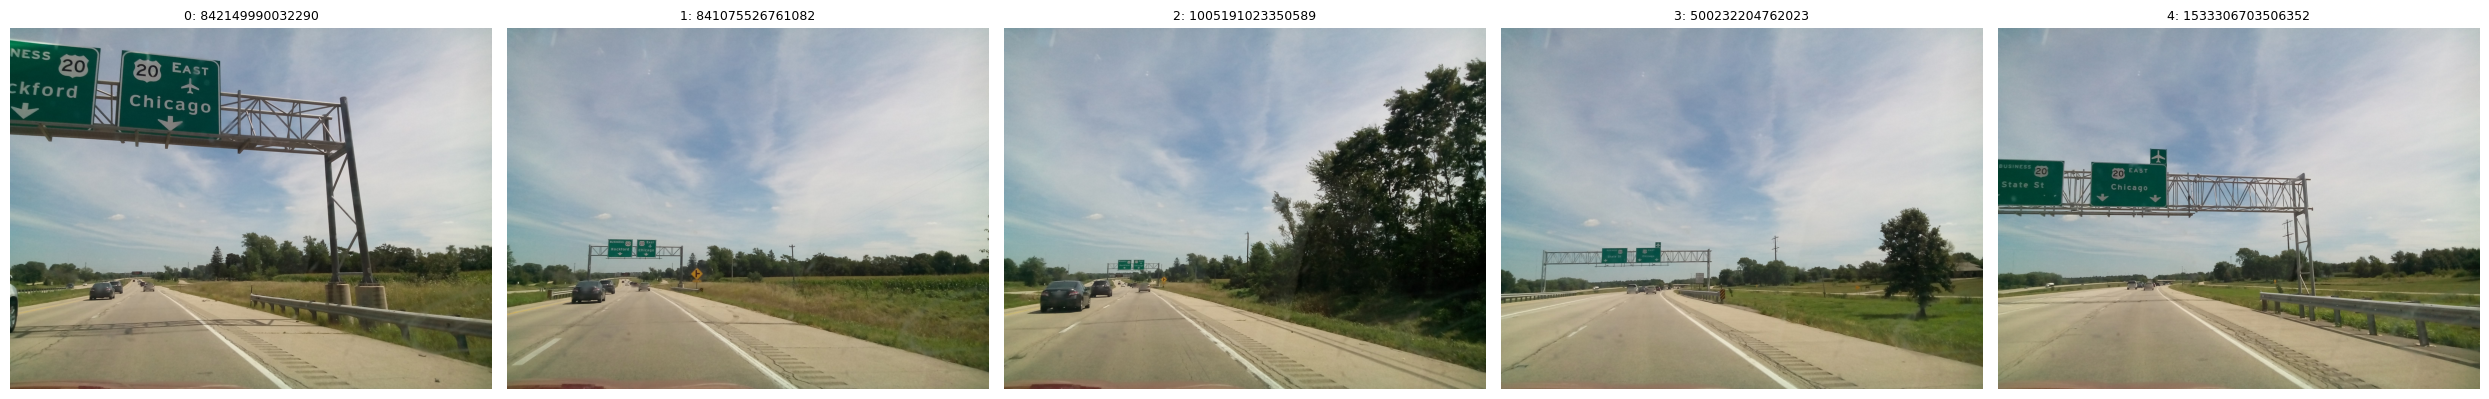

In [16]:
# =========================
# Preview selected images
# =========================

preview_paths = multi_df["local_path"].tolist()

cols = len(preview_paths)
rows = 1

plt.figure(figsize=(5 * cols, 4))

for i, path in enumerate(preview_paths):
    img = Image.open(path).convert("RGB")
    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(f"{i}: {multi_df.loc[i, 'image_id']}", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Single Image: 3D image + Measure

In [18]:
# =========================
# 0. Install / locate MapAnything
# =========================

import os
import sys
from pathlib import Path

%cd /content

# 如果 repo 不存在，就 clone
if not Path("/content/map-anything").exists():
    !git clone https://github.com/facebookresearch/map-anything.git /content/map-anything

%cd /content/map-anything

# 安装 package
!pip install -q -e .
!pip install -q opencv-python-headless matplotlib plotly trimesh pillow-heif

# 确保当前 repo 在 python path 里
if "/content/map-anything" not in sys.path:
    sys.path.insert(0, "/content/map-anything")

# test import
from mapanything.models import MapAnything
from mapanything.utils.image import load_images
from mapanything.utils.geometry import depthmap_to_world_frame

print("MapAnything import OK")
print("repo:", Path.cwd())

/content
Cloning into '/content/map-anything'...
remote: Enumerating objects: 1101, done.
remote: Counting objects: 100% (705/705), done.
remote: Compressing objects: 100% (324/324), done.
remote: Total 1101 (delta 526), reused 381 (delta 381), pack-reused 396 (from 1)
Receiving objects: 100% (1101/1101), 7.52 MiB | 33.91 MiB/s, done.
Resolving deltas: 100% (635/635), done.
/content/map-anything
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 17.4 MB/s eta 0

In [20]:
# Inspect MapAnything output structure

print("type(single_preds):", type(single_preds))
print("len(single_preds):", len(single_preds))

single_pred = single_preds[0]

print("type(single_pred):", type(single_pred))

if isinstance(single_pred, dict):
    print("single_pred keys:")
    for k, v in single_pred.items():
        if hasattr(v, "shape"):
            print(k, type(v), v.shape)
        else:
            print(k, type(v))
else:
    print(single_pred)

type(single_preds): <class 'list'>
len(single_preds): 1
type(single_pred): <class 'dict'>
single_pred keys:
pts3d <class 'torch.Tensor'> torch.Size([1, 392, 518, 3])
pts3d_cam <class 'torch.Tensor'> torch.Size([1, 392, 518, 3])
ray_directions <class 'torch.Tensor'> torch.Size([1, 392, 518, 3])
depth_along_ray <class 'torch.Tensor'> torch.Size([1, 392, 518, 1])
cam_trans <class 'torch.Tensor'> torch.Size([1, 3])
cam_quats <class 'torch.Tensor'> torch.Size([1, 4])
metric_scaling_factor <class 'torch.Tensor'> torch.Size([1, 1])
conf <class 'torch.Tensor'> torch.Size([1, 392, 518])
non_ambiguous_mask <class 'torch.Tensor'> torch.Size([1, 392, 518])
non_ambiguous_mask_logits <class 'torch.Tensor'> torch.Size([1, 392, 518])
img_no_norm <class 'torch.Tensor'> torch.Size([1, 392, 518, 3])
depth_z <class 'torch.Tensor'> torch.Size([1, 392, 518, 1])
intrinsics <class 'torch.Tensor'> torch.Size([1, 3, 3])
camera_poses <class 'torch.Tensor'> torch.Size([1, 4, 4])
mask <class 'torch.Tensor'> torch.

In [21]:
# =========================
# Extract single image 3D outputs from MapAnything prediction
# =========================

import numpy as np
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import plotly.graph_objects as go

SINGLE_OUT = EXPERIMENT_ROOT / "single_0m_3d_output"
SINGLE_OUT.mkdir(parents=True, exist_ok=True)

def tensor_to_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def squeeze_batch(x):
    x = tensor_to_numpy(x)
    if x.ndim >= 1 and x.shape[0] == 1:
        x = x[0]
    return x

single_pred = single_preds[0]

single_pts3d = squeeze_batch(single_pred["pts3d"])              # [H, W, 3]
single_pts3d_cam = squeeze_batch(single_pred["pts3d_cam"])      # [H, W, 3]
single_conf = squeeze_batch(single_pred["conf"])                # [H, W]
single_mask = squeeze_batch(single_pred["mask"]).astype(bool)   # [H, W, 1] or [H, W]
single_intrinsics = squeeze_batch(single_pred["intrinsics"])    # [3, 3]
single_camera_pose = squeeze_batch(single_pred["camera_poses"]) # [4, 4]

if single_mask.ndim == 3:
    single_mask = single_mask[..., 0]

# img_no_norm usually is [1, H, W, 3] or [H, W, 3]
single_img_model = squeeze_batch(single_pred["img_no_norm"])
single_img_model = np.asarray(single_img_model)

# handle CHW if needed
if single_img_model.ndim == 3 and single_img_model.shape[0] == 3:
    single_img_model = np.transpose(single_img_model, (1, 2, 0))

# normalize for visualization if needed
if single_img_model.max() <= 1.5:
    single_img_model_vis = (single_img_model * 255).clip(0, 255).astype(np.uint8)
else:
    single_img_model_vis = single_img_model.clip(0, 255).astype(np.uint8)

valid_single = (
    single_mask
    & np.isfinite(single_pts3d).all(axis=-1)
    & np.isfinite(single_conf)
)

np.save(SINGLE_OUT / "single_pts3d.npy", single_pts3d)
np.save(SINGLE_OUT / "single_pts3d_cam.npy", single_pts3d_cam)
np.save(SINGLE_OUT / "single_conf.npy", single_conf)
np.save(SINGLE_OUT / "single_mask.npy", single_mask)
np.save(SINGLE_OUT / "single_intrinsics.npy", single_intrinsics)
np.save(SINGLE_OUT / "single_camera_pose.npy", single_camera_pose)
np.save(SINGLE_OUT / "single_img_model.npy", single_img_model_vis)

print("pts3d:", single_pts3d.shape)
print("pts3d_cam:", single_pts3d_cam.shape)
print("conf:", single_conf.shape)
print("mask:", single_mask.shape)
print("intrinsics:", single_intrinsics.shape)
print("camera_pose:", single_camera_pose.shape)
print("valid ratio:", valid_single.mean())

pts3d: (392, 518, 3)
pts3d_cam: (392, 518, 3)
conf: (392, 518)
mask: (392, 518)
intrinsics: (3, 3)
camera_pose: (4, 4)
valid ratio: 0.39844673390591756


In [22]:
# =========================
# 3D point cloud + camera frustum visualization
# =========================

def make_rgb_pointcloud_trace(
    pts3d,
    img_rgb,
    valid_mask,
    name="point cloud",
    max_points=160000,
    marker_size=1.5,
):
    H, W = pts3d.shape[:2]

    if img_rgb.shape[:2] != (H, W):
        img_rgb = np.array(
            Image.fromarray(img_rgb.astype(np.uint8)).resize((W, H))
        )

    ys, xs = np.where(valid_mask)

    if len(xs) > max_points:
        idx = np.random.choice(len(xs), max_points, replace=False)
        xs = xs[idx]
        ys = ys[idx]

    pts = pts3d[ys, xs]
    colors = img_rgb[ys, xs].astype(np.uint8)
    color_str = [f"rgb({r},{g},{b})" for r, g, b in colors]

    return go.Scatter3d(
        x=pts[:, 0],
        y=pts[:, 1],
        z=pts[:, 2],
        mode="markers",
        marker=dict(
            size=marker_size,
            color=color_str,
            opacity=0.85,
        ),
        name=name,
    )

def make_camera_frustum_trace(camera_pose, scale=1.0, name="camera"):
    # camera center
    C = camera_pose[:3, 3]

    # simple frustum in camera local coordinates
    frustum_cam = np.array([
        [0, 0, 0],
        [-0.5, -0.35, 1.0],
        [0.5, -0.35, 1.0],
        [0.5, 0.35, 1.0],
        [-0.5, 0.35, 1.0],
    ]) * scale

    R = camera_pose[:3, :3]
    t = camera_pose[:3, 3]

    frustum_world = (R @ frustum_cam.T).T + t

    edges = [
        (0, 1), (0, 2), (0, 3), (0, 4),
        (1, 2), (2, 3), (3, 4), (4, 1),
    ]

    x, y, z = [], [], []
    for a, b in edges:
        x += [frustum_world[a, 0], frustum_world[b, 0], None]
        y += [frustum_world[a, 1], frustum_world[b, 1], None]
        z += [frustum_world[a, 2], frustum_world[b, 2], None]

    return go.Scatter3d(
        x=x,
        y=y,
        z=z,
        mode="lines",
        line=dict(width=5),
        name=name,
    )

def plot_single_3d_scene(
    pts3d,
    img_rgb,
    valid_mask,
    camera_pose=None,
    measurement_points=None,
    title="Metric-Scale 3D Reconstruction + Camera",
):
    fig = go.Figure()

    fig.add_trace(
        make_rgb_pointcloud_trace(
            pts3d,
            img_rgb,
            valid_mask,
            name="3D points",
            max_points=180000,
            marker_size=1.4,
        )
    )

    if camera_pose is not None:
        fig.add_trace(
            make_camera_frustum_trace(
                camera_pose,
                scale=1.0,
                name="camera",
            )
        )

    if measurement_points is not None:
        P1, P2 = measurement_points
        dist_m = float(np.linalg.norm(P1 - P2))
        dist_ft = dist_m * 3.28084

        fig.add_trace(
            go.Scatter3d(
                x=[P1[0], P2[0]],
                y=[P1[1], P2[1]],
                z=[P1[2], P2[2]],
                mode="lines+markers+text",
                marker=dict(size=5),
                line=dict(width=8),
                text=["top", f"{dist_ft:.2f} ft"],
                textposition="top center",
                name=f"measurement: {dist_ft:.2f} ft",
            )
        )

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Z",
            aspectmode="data",
        ),
        width=1200,
        height=850,
        margin=dict(l=0, r=0, t=50, b=0),
    )

    fig.show()
    return fig

single_fig = plot_single_3d_scene(
    pts3d=single_pts3d,
    img_rgb=single_img_model_vis,
    valid_mask=valid_single,
    camera_pose=single_camera_pose,
    measurement_points=None,
    title="Single image input: 842149990032290 - 3D reconstruction",
)

Output hidden; open in https://colab.research.google.com to view.

In [23]:
single_fig.write_html(str(SINGLE_OUT / "single_0m_3d_view.html"))
print("saved:", SINGLE_OUT / "single_0m_3d_view.html")

saved: /content/mapillary_idot_pilot/vertical_clearance_selected/single_0m_3d_output/single_0m_3d_view.html


In [28]:
# =========================
# Manual point selection -> 3D measurement
# same style as Week2_Mapanything notebook
# =========================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

single_original_img = Image.open(single_image_path).convert("RGB")
single_original_np = np.array(single_original_img)

plt.figure(figsize=(14, 9))
plt.imshow(single_original_np)
plt.axis("on")
plt.grid()
plt.title("Use this plot to read approximate pixel coordinates")
plt.show()

print("Original image shape:", single_original_np.shape)  # H, W, 3
print("MapAnything pts3d shape:", single_pts3d.shape)     # H, W, 3

<IPython.core.display.Javascript object>

Original image shape: (1920, 2560, 3)
MapAnything pts3d shape: (392, 518, 3)


In [30]:
# =========================
# Replace these with selected points: (x, y)
# coordinates are in original image pixel coordinate
# =========================

p1 = (900, 560)     # TODO: replace with your selected overhead/sign point
p2 = (900, 1600)    # TODO: replace with your selected road/ground point

plt.figure(figsize=(14, 9))
plt.imshow(single_original_np)

plt.scatter(
    [p1[0], p2[0]],
    [p1[1], p2[1]],
    c=["red", "cyan"],
    s=90,
)

plt.plot(
    [p1[0], p2[0]],
    [p1[1], p2[1]],
    color="yellow",
    linewidth=2,
)

plt.text(p1[0], p1[1], " P1", color="red", fontsize=14)
plt.text(p2[0], p2[1], " P2", color="cyan", fontsize=14)

plt.axis("on")
plt.grid()
plt.title("Manual selected points: P1 overhead/sign, P2 road/ground")
plt.show()

print("Current p1:", p1)
print("Current p2:", p2)

<IPython.core.display.Javascript object>

Current p1: (900, 560)
Current p2: (900, 1600)


In [31]:
# =========================
# Scale original coordinates to MapAnything output coordinates
# then snap to nearest valid 3D point and measure
# =========================

def scale_point_to_ma(p_xy, original_img_np, pts3d):
    x, y = p_xy

    H_img, W_img = original_img_np.shape[:2]
    H_ma, W_ma = pts3d.shape[:2]

    x_ma = int(round(x * W_ma / W_img))
    y_ma = int(round(y * H_ma / H_img))

    x_ma = max(0, min(W_ma - 1, x_ma))
    y_ma = max(0, min(H_ma - 1, y_ma))

    return (x_ma, y_ma)


def snap_to_nearest_valid(p_xy, valid_mask, max_radius=40):
    x, y = map(int, p_xy)
    H, W = valid_mask.shape

    if 0 <= x < W and 0 <= y < H and valid_mask[y, x]:
        return (x, y), 0

    for r in range(1, max_radius + 1):
        x0, x1 = max(0, x - r), min(W, x + r + 1)
        y0, y1 = max(0, y - r), min(H, y + r + 1)

        patch = valid_mask[y0:y1, x0:x1]
        ys, xs = np.where(patch)

        if len(xs) > 0:
            xs_global = xs + x0
            ys_global = ys + y0

            d2 = (xs_global - x) ** 2 + (ys_global - y) ** 2
            idx = np.argmin(d2)

            return (
                int(xs_global[idx]),
                int(ys_global[idx]),
            ), int(round(np.sqrt(d2[idx])))

    raise ValueError(
        f"No valid pixel found within radius {max_radius}. Pick another point."
    )


def measure_direct_m(pts3d, valid_mask, p1_safe, p2_safe):
    x1, y1 = p1_safe
    x2, y2 = p2_safe

    if not valid_mask[y1, x1]:
        raise ValueError("p1_safe is not valid.")
    if not valid_mask[y2, x2]:
        raise ValueError("p2_safe is not valid.")

    P1 = pts3d[y1, x1]
    P2 = pts3d[y2, x2]

    dist_m = float(np.linalg.norm(P1 - P2))

    return dist_m, P1, P2


p1_ma = scale_point_to_ma(p1, single_original_np, single_pts3d)
p2_ma = scale_point_to_ma(p2, single_original_np, single_pts3d)

p1_safe, p1_shift = snap_to_nearest_valid(
    p1_ma,
    valid_single,
    max_radius=40,
)

p2_safe, p2_shift = snap_to_nearest_valid(
    p2_ma,
    valid_single,
    max_radius=40,
)

dist_no_sam_m, P1_no_sam, P2_no_sam = measure_direct_m(
    single_pts3d,
    valid_single,
    p1_safe,
    p2_safe,
)

dist_no_sam_ft = dist_no_sam_m * 3.28084

print("p1 original:", p1, "-> p1_ma:", p1_ma, "-> p1_safe:", p1_safe, "shift_px:", p1_shift)
print("p2 original:", p2, "-> p2_ma:", p2_ma, "-> p2_safe:", p2_safe, "shift_px:", p2_shift)

print("No SAM result")
print(f"Distance: {dist_no_sam_m:.3f} m")
print(f"Distance: {dist_no_sam_ft:.3f} ft")
print("P1 3D:", P1_no_sam)
print("P2 3D:", P2_no_sam)

p1 original: (900, 560) -> p1_ma: (182, 114) -> p1_safe: (182, 114) shift_px: 0
p2 original: (900, 1600) -> p2_ma: (182, 327) -> p2_safe: (183, 327) shift_px: 1
No SAM result
Distance: 4.756 m
Distance: 15.604 ft
P1 3D: [-1.7884755 -1.917276   7.8578787]
P2 3D: [-1.6109015  2.797946   7.260776 ]


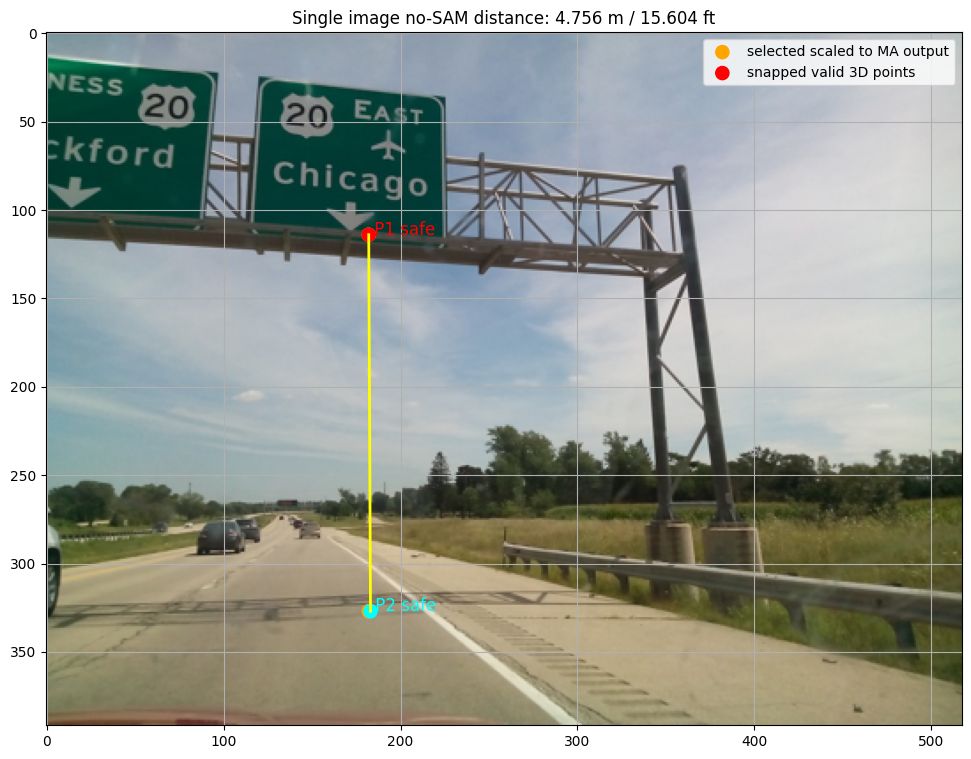

In [35]:
# =========================
# Visualize selected vs snapped points on MapAnything output resolution
# =========================

%matplotlib inline

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

plt.close("all")

H_ma, W_ma = single_pts3d.shape[:2]

img_ma_np = np.array(
    Image.fromarray(single_original_np.astype(np.uint8)).resize((W_ma, H_ma))
)

plt.figure(figsize=(14, 9))
plt.imshow(img_ma_np)

plt.scatter(
    [p1_ma[0], p2_ma[0]],
    [p1_ma[1], p2_ma[1]],
    c=["orange", "orange"],
    s=90,
    label="selected scaled to MA output",
)

plt.scatter(
    [p1_safe[0], p2_safe[0]],
    [p1_safe[1], p2_safe[1]],
    c=["red", "cyan"],
    s=90,
    label="snapped valid 3D points",
)

plt.plot(
    [p1_safe[0], p2_safe[0]],
    [p1_safe[1], p2_safe[1]],
    color="yellow",
    linewidth=2,
)

plt.text(p1_safe[0], p1_safe[1], " P1 safe", color="red", fontsize=12)
plt.text(p2_safe[0], p2_safe[1], " P2 safe", color="cyan", fontsize=12)

plt.title(
    f"Single image no-SAM distance: "
    f"{dist_no_sam_m:.3f} m / {dist_no_sam_ft:.3f} ft"
)

plt.legend()
plt.axis("on")
plt.grid()
plt.show()

In [36]:
# =========================
# Add measurement line to 3D view
# =========================

single_fig_measured = plot_single_3d_scene(
    pts3d=single_pts3d,
    img_rgb=single_img_model_vis,
    valid_mask=valid_single,
    camera_pose=single_camera_pose,
    measurement_points=(
        P1_no_sam,
        P2_no_sam,
    ),
    title=f"Single image 3D reconstruction + measurement: {dist_no_sam_ft:.2f} ft",
)

single_fig_measured.write_html(
    str(SINGLE_OUT / "single_0m_3d_measurement.html")
)

print("saved:", SINGLE_OUT / "single_0m_3d_measurement.html")

Output hidden; open in https://colab.research.google.com to view.

# Multiple Image - 3D + Measure

In [37]:
# =========================
# Multiple image input -> MapAnything 3D
# =========================

MULTI_OUT = EXPERIMENT_ROOT / "multi_selected_3d_output"
MULTI_OUT.mkdir(parents=True, exist_ok=True)

multi_paths = multi_df["local_path"].tolist()

print("multi_paths:")
for p in multi_paths:
    print(p)

multi_images = load_images(multi_paths)

with torch.no_grad():
    multi_preds = model.infer(
        multi_images,
        confidence_percentile=50,
    )

print("num predictions:", len(multi_preds))
print("keys:", multi_preds[0].keys())

multi_paths:
/content/mapillary_idot_pilot/vertical_clearance_selected/multi_input/mapillary_842149990032290.jpg
/content/mapillary_idot_pilot/vertical_clearance_selected/multi_input/mapillary_841075526761082.jpg
/content/mapillary_idot_pilot/vertical_clearance_selected/multi_input/mapillary_1005191023350589.jpg
/content/mapillary_idot_pilot/vertical_clearance_selected/multi_input/mapillary_500232204762023.jpg
/content/mapillary_idot_pilot/vertical_clearance_selected/multi_input/mapillary_1533306703506352.jpg
num predictions: 5
keys: dict_keys(['pts3d', 'pts3d_cam', 'ray_directions', 'depth_along_ray', 'cam_trans', 'cam_quats', 'metric_scaling_factor', 'conf', 'non_ambiguous_mask', 'non_ambiguous_mask_logits', 'img_no_norm', 'depth_z', 'intrinsics', 'camera_poses', 'mask'])


In [38]:
# =========================
# Extract and save multiple image outputs
# =========================

multi_records = []

for i, pred in enumerate(multi_preds):
    image_path = multi_paths[i]
    image_id = Path(image_path).stem.replace("mapillary_", "")

    pts3d = squeeze_batch(pred["pts3d"])
    pts3d_cam = squeeze_batch(pred["pts3d_cam"])
    conf = squeeze_batch(pred["conf"])
    mask = squeeze_batch(pred["mask"]).astype(bool)
    intrinsics = squeeze_batch(pred["intrinsics"])
    camera_pose = squeeze_batch(pred["camera_poses"])
    img_model = squeeze_batch(pred["img_no_norm"])

    if mask.ndim == 3:
        mask = mask[..., 0]

    if img_model.ndim == 3 and img_model.shape[0] == 3:
        img_model = np.transpose(img_model, (1, 2, 0))

    if img_model.max() <= 1.5:
        img_model_vis = (img_model * 255).clip(0, 255).astype(np.uint8)
    else:
        img_model_vis = img_model.clip(0, 255).astype(np.uint8)

    valid = (
        mask
        & np.isfinite(pts3d).all(axis=-1)
        & np.isfinite(conf)
    )

    np.save(MULTI_OUT / f"{i:02d}_{image_id}_pts3d.npy", pts3d)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_pts3d_cam.npy", pts3d_cam)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_conf.npy", conf)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_mask.npy", mask)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_valid.npy", valid)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_intrinsics.npy", intrinsics)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_camera_pose.npy", camera_pose)
    np.save(MULTI_OUT / f"{i:02d}_{image_id}_img_model.npy", img_model_vis)

    multi_records.append({
        "index": i,
        "image_id": image_id,
        "image_path": image_path,
        "pts3d_path": str(MULTI_OUT / f"{i:02d}_{image_id}_pts3d.npy"),
        "mask_path": str(MULTI_OUT / f"{i:02d}_{image_id}_mask.npy"),
        "valid_path": str(MULTI_OUT / f"{i:02d}_{image_id}_valid.npy"),
        "img_model_path": str(MULTI_OUT / f"{i:02d}_{image_id}_img_model.npy"),
        "camera_pose_path": str(MULTI_OUT / f"{i:02d}_{image_id}_camera_pose.npy"),
        "valid_ratio": float(valid.mean()),
    })

multi_out_df = pd.DataFrame(multi_records)
multi_out_df.to_csv(MULTI_OUT / "multi_outputs_manifest.csv", index=False)

display(multi_out_df)

,index,image_id,image_path,pts3d_path,mask_path,valid_path,img_model_path,camera_pose_path,valid_ratio
0,0,842149990032290,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,0.358541
1,1,841075526761082,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,0.188189
2,2,1005191023350589,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,0.374030
3,3,500232204762023,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,0.179798
4,4,1533306703506352,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,/content/mapillary_idot_pilot/vertical_clearan...,0.258855


In [39]:
# =========================
# Multiple image merged 3D view
# =========================

import plotly.graph_objects as go
import numpy as np
from PIL import Image

def add_cloud_trace_from_saved(
    fig,
    row,
    max_points=50000,
    marker_size=1.2,
):
    pts3d = np.load(row["pts3d_path"])
    valid = np.load(row["valid_path"])
    img_rgb = np.load(row["img_model_path"])

    H, W = pts3d.shape[:2]

    if img_rgb.shape[:2] != (H, W):
        img_rgb = np.array(
            Image.fromarray(img_rgb.astype(np.uint8)).resize((W, H))
        )

    ys, xs = np.where(valid)

    if len(xs) == 0:
        print("No valid points:", row["image_id"])
        return fig

    if len(xs) > max_points:
        idx = np.random.choice(len(xs), max_points, replace=False)
        xs = xs[idx]
        ys = ys[idx]

    pts = pts3d[ys, xs]
    colors = img_rgb[ys, xs].astype(np.uint8)
    color_str = [f"rgb({r},{g},{b})" for r, g, b in colors]

    fig.add_trace(
        go.Scatter3d(
            x=pts[:, 0],
            y=pts[:, 1],
            z=pts[:, 2],
            mode="markers",
            marker=dict(
                size=marker_size,
                color=color_str,
                opacity=0.75,
            ),
            name=row["image_id"],
        )
    )

    return fig


multi_fig = go.Figure()

for _, row in multi_out_df.iterrows():
    multi_fig = add_cloud_trace_from_saved(
        multi_fig,
        row,
        max_points=50000,
        marker_size=1.2,
    )

multi_fig.update_layout(
    title="Multiple image input - merged 3D reconstruction",
    scene=dict(
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        aspectmode="data",
    ),
    width=1200,
    height=850,
    margin=dict(l=0, r=0, t=50, b=0),
)

multi_fig.show()

multi_fig.write_html(str(MULTI_OUT / "multi_selected_merged_3d_view.html"))
print("saved:", MULTI_OUT / "multi_selected_merged_3d_view.html")

Output hidden; open in https://colab.research.google.com to view.

In [40]:
# =========================
# Measure on 0m frame inside multiple image run
# using same p1 / p2 as single image
# =========================

SINGLE_IMAGE_ID = "842149990032290"

multi_0m_row = multi_out_df[
    multi_out_df["image_id"] == SINGLE_IMAGE_ID
].iloc[0]

multi_0m_pts3d = np.load(multi_0m_row["pts3d_path"])
multi_0m_valid = np.load(multi_0m_row["valid_path"])
multi_0m_img_model = np.load(multi_0m_row["img_model_path"])

# original image for coordinate scaling
multi_0m_original_img = Image.open(multi_0m_row["image_path"]).convert("RGB")
multi_0m_original_np = np.array(multi_0m_original_img)

p1_multi_ma = scale_point_to_ma(p1, multi_0m_original_np, multi_0m_pts3d)
p2_multi_ma = scale_point_to_ma(p2, multi_0m_original_np, multi_0m_pts3d)

p1_multi_safe, p1_multi_shift = snap_to_nearest_valid(
    p1_multi_ma,
    multi_0m_valid,
    max_radius=40,
)

p2_multi_safe, p2_multi_shift = snap_to_nearest_valid(
    p2_multi_ma,
    multi_0m_valid,
    max_radius=40,
)

dist_multi_m, P1_multi, P2_multi = measure_direct_m(
    multi_0m_pts3d,
    multi_0m_valid,
    p1_multi_safe,
    p2_multi_safe,
)

dist_multi_ft = dist_multi_m * 3.28084

print("Multiple image run, measured on 0m frame")
print("p1 original:", p1, "-> p1_ma:", p1_multi_ma, "-> p1_safe:", p1_multi_safe, "shift_px:", p1_multi_shift)
print("p2 original:", p2, "-> p2_ma:", p2_multi_ma, "-> p2_safe:", p2_multi_safe, "shift_px:", p2_multi_shift)
print(f"Distance: {dist_multi_m:.3f} m")
print(f"Distance: {dist_multi_ft:.3f} ft")
print("P1 3D:", P1_multi)
print("P2 3D:", P2_multi)

Multiple image run, measured on 0m frame
p1 original: (900, 560) -> p1_ma: (182, 114) -> p1_safe: (182, 114) shift_px: 0
p2 original: (900, 1600) -> p2_ma: (182, 327) -> p2_safe: (182, 327) shift_px: 0
Distance: 5.806 m
Distance: 19.048 ft
P1 3D: [-2.199014  -2.3454943 11.250661 ]
P2 3D: [-1.9256245  3.294819   9.901446 ]


In [41]:
# =========================
# Compare single vs multiple measurement
# =========================

comparison_df = pd.DataFrame([
    {
        "run": "single_0m_input",
        "image_id": SINGLE_IMAGE_ID,
        "p1": p1,
        "p2": p2,
        "distance_m": dist_no_sam_m,
        "distance_ft": dist_no_sam_ft,
        "p1_safe": p1_safe,
        "p2_safe": p2_safe,
    },
    {
        "run": "multiple_input_measured_on_0m",
        "image_id": SINGLE_IMAGE_ID,
        "p1": p1,
        "p2": p2,
        "distance_m": dist_multi_m,
        "distance_ft": dist_multi_ft,
        "p1_safe": p1_multi_safe,
        "p2_safe": p2_multi_safe,
    },
])

GT_CLEARANCE_FT = None  # TODO: fill IDOT ground truth, e.g. 15.0

if GT_CLEARANCE_FT is not None:
    comparison_df["gt_ft"] = GT_CLEARANCE_FT
    comparison_df["error_ft"] = comparison_df["distance_ft"] - GT_CLEARANCE_FT
    comparison_df["abs_error_ft"] = comparison_df["error_ft"].abs()
    comparison_df["pct_error"] = comparison_df["abs_error_ft"] / GT_CLEARANCE_FT * 100

display(comparison_df)

comparison_df.to_csv(
    EXPERIMENT_ROOT / "single_vs_multiple_measurement_comparison.csv",
    index=False,
)

print("saved:", EXPERIMENT_ROOT / "single_vs_multiple_measurement_comparison.csv")

,run,image_id,p1,p2,distance_m,distance_ft,p1_safe,p2_safe
0,single_0m_input,842149990032290,"(900, 560)","(900, 1600)",4.756194,15.604312,"(182, 114)","(183, 327)"
1,multiple_input_measured_on_0m,842149990032290,"(900, 560)","(900, 1600)",5.805881,19.048167,"(182, 114)","(182, 327)"


saved: /content/mapillary_idot_pilot/vertical_clearance_selected/single_vs_multiple_measurement_comparison.csv


In [42]:
# =========================
# 3D view for multiple run measured on 0m frame only
# =========================

multi_0m_camera_pose = np.load(multi_0m_row["camera_pose_path"])

multi_0m_fig_measured = plot_single_3d_scene(
    pts3d=multi_0m_pts3d,
    img_rgb=multi_0m_img_model,
    valid_mask=multi_0m_valid,
    camera_pose=multi_0m_camera_pose,
    measurement_points=(
        P1_multi,
        P2_multi,
    ),
    title=f"Multiple image run, 0m frame measurement: {dist_multi_ft:.2f} ft",
)

multi_0m_fig_measured.write_html(
    str(MULTI_OUT / "multi_run_0m_frame_3d_measurement.html")
)

print("saved:", MULTI_OUT / "multi_run_0m_frame_3d_measurement.html")

Output hidden; open in https://colab.research.google.com to view.

# Adding SAM3

In [46]:
# =========================
# 1. Correct SAM3 image API: Sam3Processor
# =========================

import os
import sys
from pathlib import Path
import torch
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

%cd /content/sam3

if "/content/sam3" not in sys.path:
    sys.path.insert(0, "/content/sam3")

from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# This may download model checkpoint from Hugging Face.
# If it asks for access / auth, you need Hugging Face access to facebook/sam3.
sam3_model = build_sam3_image_model()
sam3_model = sam3_model.to(device)
sam3_model.eval()

sam3_processor = Sam3Processor(sam3_model)

print("SAM3 image processor ready")

/content/sam3
device: cuda


GatedRepoError: 401 Client Error. (Request ID: Root=1-6a0de5e5-7dd919a30318a3be3f4437e0;b57e6c5c-4fea-4bca-a02e-9bd5b1f3d47c)

Cannot access gated repo for url https://huggingface.co/facebook/sam3/resolve/main/config.json.
Access to model facebook/sam3 is restricted. You must have access to it and be authenticated to access it. Please log in.

In [44]:
# =========================
# Inspect SAM3 API
# =========================

import os
from pathlib import Path

repo = Path("/content/sam3")

print("Top-level files:")
for p in repo.iterdir():
    print(p.name)

print("\nPython files likely related to predictors:")
for p in repo.rglob("*.py"):
    name = str(p.relative_to(repo))
    if any(k in name.lower() for k in ["predict", "build", "model", "image"]):
        print(name)

Top-level files:
.github
.gitignore
.git
README_TRAIN.md
sam3
examples
RELEASE_SAM3p1.md
MANIFEST.in
pyproject.toml
CODE_OF_CONDUCT.md
LICENSE
README.md
test
CONTRIBUTING.md
sam3.egg-info
assets
scripts

Python files likely related to predictors:
sam3/model_builder.py
sam3/model/sam3_image_processor.py
sam3/model/necks.py
sam3/model/sam3_multiplex_base.py
sam3/model/sam3_multiplex_tracking.py
sam3/model/sam3_multiplex_video_predictor.py
sam3/model/tokenizer_ve.py
sam3/model/sam3_base_predictor.py
sam3/model/sam3_video_base.py
sam3/model/memory.py
sam3/model/sam1_task_predictor.py
sam3/model/maskformer_segmentation.py
sam3/model/position_encoding.py
sam3/model/model_misc.py
sam3/model/multiplex_mask_decoder.py
sam3/model/__init__.py
sam3/model/act_ckpt_utils.py
sam3/model/io_utils.py
sam3/model/sam3_video_predictor.py
sam3/model/geometry_encoders.py
sam3/model/multiplex_utils.py
sam3/model/sam3_tracker_utils.py
sam3/model/video_tracking_multiplex.py
sam3/model/data_misc.py
sam3/model/vl

In [45]:
# =========================
# Try loading SAM3 image predictor
# =========================

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Try common SAM3 API names.
sam3_model = None
sam3_predictor = None

try:
    from sam3.model_builder import build_sam3_image_model
    from sam3.sam3_image_predictor import SAM3ImagePredictor

    sam3_model = build_sam3_image_model(device=device)
    sam3_predictor = SAM3ImagePredictor(sam3_model)

    print("Loaded SAM3 via sam3.model_builder + SAM3ImagePredictor")

except Exception as e1:
    print("First SAM3 import path failed:")
    print(type(e1), e1)

    try:
        from sam3.build_sam import build_sam3
        from sam3.predictor import SAM3Predictor

        sam3_model = build_sam3(device=device)
        sam3_predictor = SAM3Predictor(sam3_model)

        print("Loaded SAM3 via sam3.build_sam + SAM3Predictor")

    except Exception as e2:
        print("Second SAM3 import path failed:")
        print(type(e2), e2)
        raise RuntimeError("Need to adapt to this SAM3 repo API. Send this error output.")

device: cuda
First SAM3 import path failed:
<class 'ModuleNotFoundError'> No module named 'sam3.sam3_image_predictor'
Second SAM3 import path failed:
<class 'ModuleNotFoundError'> No module named 'sam3.build_sam'


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning:

Importing from timm.models.layers is deprecated, please import via timm.layers



RuntimeError: Need to adapt to this SAM3 repo API. Send this error output.